In [6]:
# =============================================================================
# PART 1: IMPORT DATA LOADING
# =============================================================================
import importlib
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
project_dir = next(
    d for d in [Path.cwd(), *Path.cwd().parents] if (d / "functions.py").exists()
)
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

import functions
importlib.reload(functions)

from functions import (
    black_76,
    build_fixing_schedule,
    collar_value,
    discount_factor,
    estimate_rho_rolling,
    fixing_thetas,
    futures_expiry,
    get_smile,
    price_asian,
    read_vol,
    solve_put_strike,
)

candidates = [
    project_dir / "unpivoted_bid_offer_train_clean.parquet",
    project_dir / "mes_donnees.csv",
]
path = next(p for p in candidates if p.exists())
df = pd.read_parquet(path) if path.suffix == ".parquet" else pd.read_csv(path)
df["date"] = pd.to_datetime(df["date"])

# Forward-fill SOFR on US market holidays
sofr = df.groupby("date")["sofr_rate"].first().ffill()
df["sofr_rate"] = df["date"].map(sofr)

# Contract specification (in-sample: Feb 2021 averaging on Apr21 / May21 futures)
valuation_date = pd.Timestamp("2020-01-06")
tickers = ["COJ21 Comdty", "COK21 Comdty"]
K_call = 78.0
notional = 1_000_000

futures_prices = (
    df[["date", "underlying_ticker", "underlying_settlement"]]
    .drop_duplicates(subset=["date", "underlying_ticker"])
    .pivot(index="date", columns="underlying_ticker", values="underlying_settlement")
    .sort_index()
)
futures_prices.index = pd.to_datetime(futures_prices.index)
log_returns = np.log(futures_prices[tickers]).diff()

d0 = df[df["date"] == valuation_date]
f1_0 = futures_prices.at[valuation_date, tickers[0]]
f2_0 = futures_prices.at[valuation_date, tickers[1]]
print(f"Data file: {path.name} | {valuation_date.date()} | Apr21={f1_0:.2f} $ | May21={f2_0:.2f} $")

Data file: unpivoted_bid_offer_train_clean.parquet | 2020-01-06 | Apr21=61.40 $ | May21=61.05 $


ICE Brent options are American-style but futures-style margined: premiums are marked to market daily rather than paid upfront. Early exercise is therefore never optimal and the American price equals the undiscounted European Black-76 price ($r = 0$, Asay 1982). The OTC Asian collar settles in cash at maturity $T$ and is discounted using the SOFR curve $D(t, T)$.

In [7]:
# =============================================================================
# PART 2: FIXING SCHEDULE (ICE BRENT ROLL RULE - ANNEX B)
# =============================================================================

fixing_dates, n1_sched, n2_sched = build_fixing_schedule(2021, 2, tickers[0])
payment_date = fixing_dates[-1]
theta_1_0, theta_2_0 = fixing_thetas(fixing_dates, n1_sched, valuation_date)

print("Apr21 futures expiry:", futures_expiry(tickers[0]).date())
print(
    f"Fixings: N = {len(fixing_dates)} | "
    f"Apr21: {n1_sched} ({fixing_dates[0].date()} -> {fixing_dates[n1_sched - 1].date()}) | "
    f"May21: {n2_sched} ({fixing_dates[n1_sched].date()} -> {fixing_dates[-1].date()})"
)

Apr21 futures expiry: 2021-02-26
Fixings: N = 20 | Apr21: 18 (2021-02-01 -> 2021-02-24) | May21: 2 (2021-02-25 -> 2021-02-26)


Apr21: 8 liquid OTM quotes (strikes 45 to 80)
May21: 8 liquid OTM quotes (strikes 45 to 80)


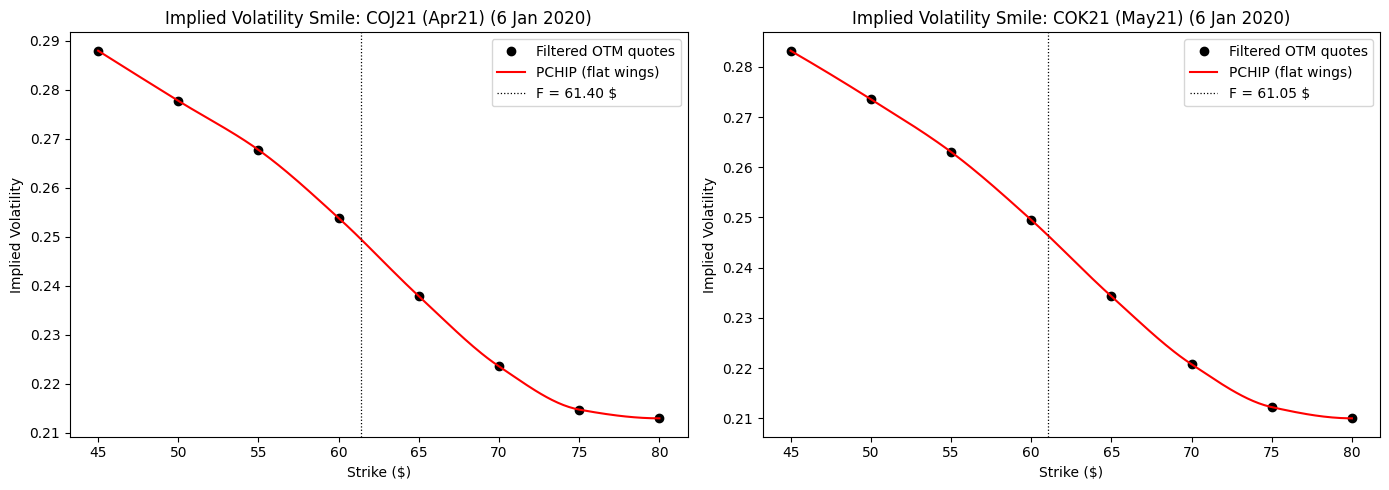

In [8]:
# =============================================================================
# PART 3: SMILE CALIBRATION AS OF 6 JANUARY 2020 (OTM LIQUIDITY FILTER + PCHIP)
# =============================================================================
smile1_0 = get_smile(d0, tickers[0])
smile2_0 = get_smile(d0, tickers[1])

print(
    f"Apr21: {len(smile1_0['strikes'])} liquid OTM quotes "
    f"(strikes {smile1_0['strikes'][0]:.0f} to {smile1_0['strikes'][-1]:.0f})"
)
print(
    f"May21: {len(smile2_0['strikes'])} liquid OTM quotes "
    f"(strikes {smile2_0['strikes'][0]:.0f} to {smile2_0['strikes'][-1]:.0f})"
)

plt.figure(figsize=(14, 5))
for i, (smile, name) in enumerate([(smile1_0, "COJ21 (Apr21)"), (smile2_0, "COK21 (May21)")]):
    plt.subplot(1, 2, i + 1)
    grid = np.linspace(smile["strikes"][0], smile["strikes"][-1], 200)
    plt.plot(smile["strikes"], smile["vols"], "ko", label="Filtered OTM quotes")
    plt.plot(grid, [read_vol(smile, k) for k in grid], "r-", label="PCHIP (flat wings)")
    plt.axvline(smile["F"], color="k", ls=":", lw=0.9, label=f"F = {smile['F']:.2f} $")
    plt.title(f"Implied Volatility Smile: {name} (6 Jan 2020)")
    plt.xlabel("Strike ($)")
    plt.ylabel("Implied Volatility")
    plt.legend()
plt.tight_layout()
plt.show()

In [9]:
# =============================================================================
# PART 4: ZERO-COST ASIAN COLLAR PRICING AS OF 6 JANUARY 2020
# =============================================================================
rho_0 = estimate_rho_rolling(log_returns, tickers, valuation_date)
D_0 = discount_factor(d0, valuation_date, payment_date)

w1 = n1_sched / len(fixing_dates)
w2 = n2_sched / len(fixing_dates)
F_avg_0 = w1 * f1_0 + w2 * f2_0

call_0 = price_asian(K_call, "call", f1_0, f2_0, smile1_0, smile2_0, rho_0, theta_1_0, theta_2_0, D_0)
K_put_0 = solve_put_strike(call_0, f1_0, f2_0, smile1_0, smile2_0, rho_0, theta_1_0, theta_2_0, D_0, K_call=K_call)
put_0 = price_asian(K_put_0, "put", f1_0, f2_0, smile1_0, smile2_0, rho_0, theta_1_0, theta_2_0, D_0)

print("--- PRICING RESULTS (6 JANUARY 2020) ---")
print(f"Initial correlation rho  : {rho_0:.4f}")
print(f"Basket forward F_avg     : {F_avg_0:.3f} $")
print(f"SOFR discount factor D_0 : {D_0:.5f} (SOFR {d0['sofr_rate'].iloc[0]:.2f}%)")
print(f"Call(78)                 : {call_0:.4f} $/bbl ({call_0 * notional:,.0f} $ on 1M bbl)")
print(f"Zero-cost put strike     : {K_put_0:.4f} $")
print(f"Put(K_put)               : {put_0:.4f} $/bbl (gap = {put_0 - call_0:+.2e} $)")

--- PRICING RESULTS (6 JANUARY 2020) ---
Initial correlation rho  : 0.9900
Basket forward F_avg     : 61.365 $
SOFR discount factor D_0 : 0.98245 (SOFR 1.55%)
Call(78)                 : 1.0831 $/bbl (1,083,091 $ on 1M bbl)
Zero-cost put strike     : 44.2990 $
Put(K_put)               : 1.0831 $/bbl (gap = -2.37e-10 $)


In [10]:
# =============================================================================
# PART 4B: SMOKE TEST (MONTE CARLO VALIDATION ON SINGLE-LEG ASIAN CALL)
# =============================================================================
theta_1_smoke = theta_1_0 + theta_2_0
n1_smoke = len(theta_1_smoke)
sigma1_smoke = read_vol(smile1_0, K_call)

# Analytical moment-matching price (single leg, undiscounted)
var_smoke = sum(
    (2 * (n1_smoke - k) + 1) * (math.exp(sigma1_smoke**2 * theta_1_smoke[k - 1]) - 1)
    for k in range(1, n1_smoke + 1)
) * (f1_0**2 / n1_smoke**2)
v_smoke = math.sqrt(math.log(1 + (var_smoke / (f1_0**2))))
price_smoke = black_76(f1_0, K_call, v_smoke, 0, 1.0, option_type="call")

# Exact lognormal Monte Carlo simulation
num_simulations = int(1e6)
np.random.seed(42)
Z = np.random.standard_normal((num_simulations, n1_smoke))

paths = np.zeros((num_simulations, n1_smoke))
current_prices = np.full(num_simulations, f1_0)

for k in range(n1_smoke):
    t_prev = 0.0 if k == 0 else theta_1_smoke[k - 1]
    dt = theta_1_smoke[k] - t_prev
    dW = np.sqrt(dt) * Z[:, k]
    current_prices = current_prices * np.exp(-0.5 * (sigma1_smoke**2) * dt + sigma1_smoke * dW)
    paths[:, k] = current_prices

simulated_averages = np.mean(paths, axis=1)
payoffs = np.maximum(simulated_averages - K_call, 0.0)
price_monte_carlo = np.mean(payoffs)

print("--- MONTE CARLO SMOKE TEST RESULTS ---")
print(f"Moment-Matching Asian Call Price : {price_smoke:.4f} $")
print(f"Monte Carlo Asian Call Price     : {price_monte_carlo:.4f} $")
print(f"Absolute Pricing Difference      : {abs(price_smoke - price_monte_carlo):.4f} $")
if abs(price_smoke - price_monte_carlo) < 0.03:
    print("STATUS: PASSED (Moment-matching matches Monte Carlo)")
else:
    print("STATUS: FAILED")

--- MONTE CARLO SMOKE TEST RESULTS ---
Moment-Matching Asian Call Price : 1.1160 $
Monte Carlo Asian Call Price     : 1.1162 $
Absolute Pricing Difference      : 0.0002 $
STATUS: PASSED (Moment-matching matches Monte Carlo)


Calibrated days: 297 (2020-01-06 -> 2021-02-26)
Stale smile days: Apr21=18, May21=0
Days without bid/ask (settlement only): 0


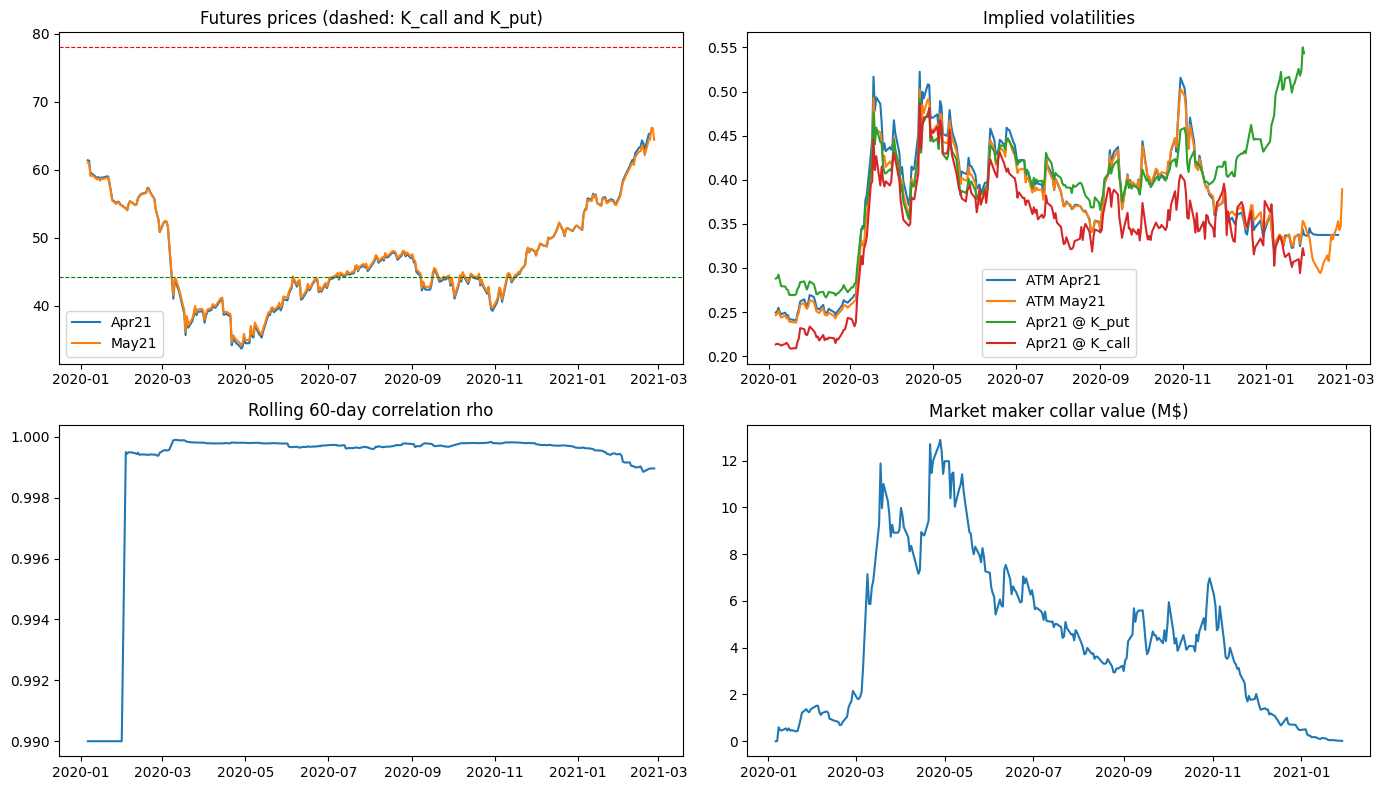

In [11]:
# =============================================================================
# PART 5: DAILY CALIBRATION OVER THE TRAINING DATASET
# =============================================================================
calibration = []
last_smiles = {}
smiles_by_day = {}

for day, day_data in df.groupby("date"):
    day = pd.Timestamp(day)
    if day > fixing_dates[-1]:
        break

    smiles, stale = {}, {}
    for contract in tickers:
        smile = get_smile(day_data, contract)
        stale[contract] = smile is None
        if smile is None:
            smile = last_smiles.get(contract)
        last_smiles[contract] = smile
        smiles[contract] = smile
    smiles_by_day[day] = smiles

    f1_t, f2_t = futures_prices.at[day, tickers[0]], futures_prices.at[day, tickers[1]]
    rho_t = estimate_rho_rolling(log_returns, tickers, day)
    row = {
        "date": day,
        "f1": f1_t,
        "f2": f2_t,
        "rho": rho_t,
        "n_quotes_1": 0 if stale[tickers[0]] else len(smiles[tickers[0]]["strikes"]),
        "n_quotes_2": 0 if stale[tickers[1]] else len(smiles[tickers[1]]["strikes"]),
        "stale_1": stale[tickers[0]],
        "stale_2": stale[tickers[1]],
        "has_bid_ask": day_data["option_bid"].notna().any(),
    }

    if smiles[tickers[0]] is not None and np.isfinite(f1_t):
        row["atm_vol_1"] = read_vol(smiles[tickers[0]], f1_t)
    if smiles[tickers[1]] is not None and np.isfinite(f2_t):
        row["atm_vol_2"] = read_vol(smiles[tickers[1]], f2_t)

    if day < fixing_dates[0]:
        D_t = discount_factor(day_data, day, payment_date)
        th1, th2 = fixing_thetas(fixing_dates, n1_sched, day)
        call_t = price_asian(K_call, "call", f1_t, f2_t, smiles[tickers[0]], smiles[tickers[1]], rho_t, th1, th2, D_t)
        put_t = price_asian(K_put_0, "put", f1_t, f2_t, smiles[tickers[0]], smiles[tickers[1]], rho_t, th1, th2, D_t)
        F_avg_t = (n1_sched * f1_t + n2_sched * f2_t) / (n1_sched + n2_sched)
        row.update({
            "D": D_t,
            "F_avg": F_avg_t,
            "sigma1_call": read_vol(smiles[tickers[0]], f1_t * K_call / F_avg_t),
            "sigma1_put": read_vol(smiles[tickers[0]], f1_t * K_put_0 / F_avg_t),
            "call": call_t,
            "put": put_t,
            "collar_value": notional * (put_t - call_t),
        })
    calibration.append(row)

calibration = pd.DataFrame(calibration).set_index("date")
print(f"Calibrated days: {len(calibration)} ({calibration.index[0].date()} -> {calibration.index[-1].date()})")
print(f"Stale smile days: Apr21={calibration['stale_1'].sum()}, May21={calibration['stale_2'].sum()}")
print(f"Days without bid/ask (settlement only): {(~calibration['has_bid_ask']).sum()}")

fig, ax = plt.subplots(2, 2, figsize=(14, 8))
ax[0, 0].plot(calibration[["f1", "f2"]])
ax[0, 0].axhline(K_call, color="r", ls="--", lw=0.8)
ax[0, 0].axhline(K_put_0, color="g", ls="--", lw=0.8)
ax[0, 0].set_title("Futures prices (dashed: K_call and K_put)")
ax[0, 0].legend(["Apr21", "May21"])

ax[0, 1].plot(calibration[["atm_vol_1", "atm_vol_2", "sigma1_put", "sigma1_call"]])
ax[0, 1].set_title("Implied volatilities")
ax[0, 1].legend(["ATM Apr21", "ATM May21", "Apr21 @ K_put", "Apr21 @ K_call"])

ax[1, 0].plot(calibration["rho"])
ax[1, 0].set_title("Rolling 60-day correlation rho")

ax[1, 1].plot(calibration["collar_value"] / 1e6)
ax[1, 1].set_title("Market maker collar value (M$)")

plt.tight_layout()
plt.show()

--- DELTA HEDGING RESULTS (6 JAN 2020 -> 29 JAN 2021) ---
Mean squared daily P&L : 22,533,044,725 $^2
RMS daily P&L          : 150,110 $
Worst day              : -570,835 $
Best day               : 1,219,727 $
Total bid-ask costs    : 90,563 $
Final portfolio value  : 878,119 $


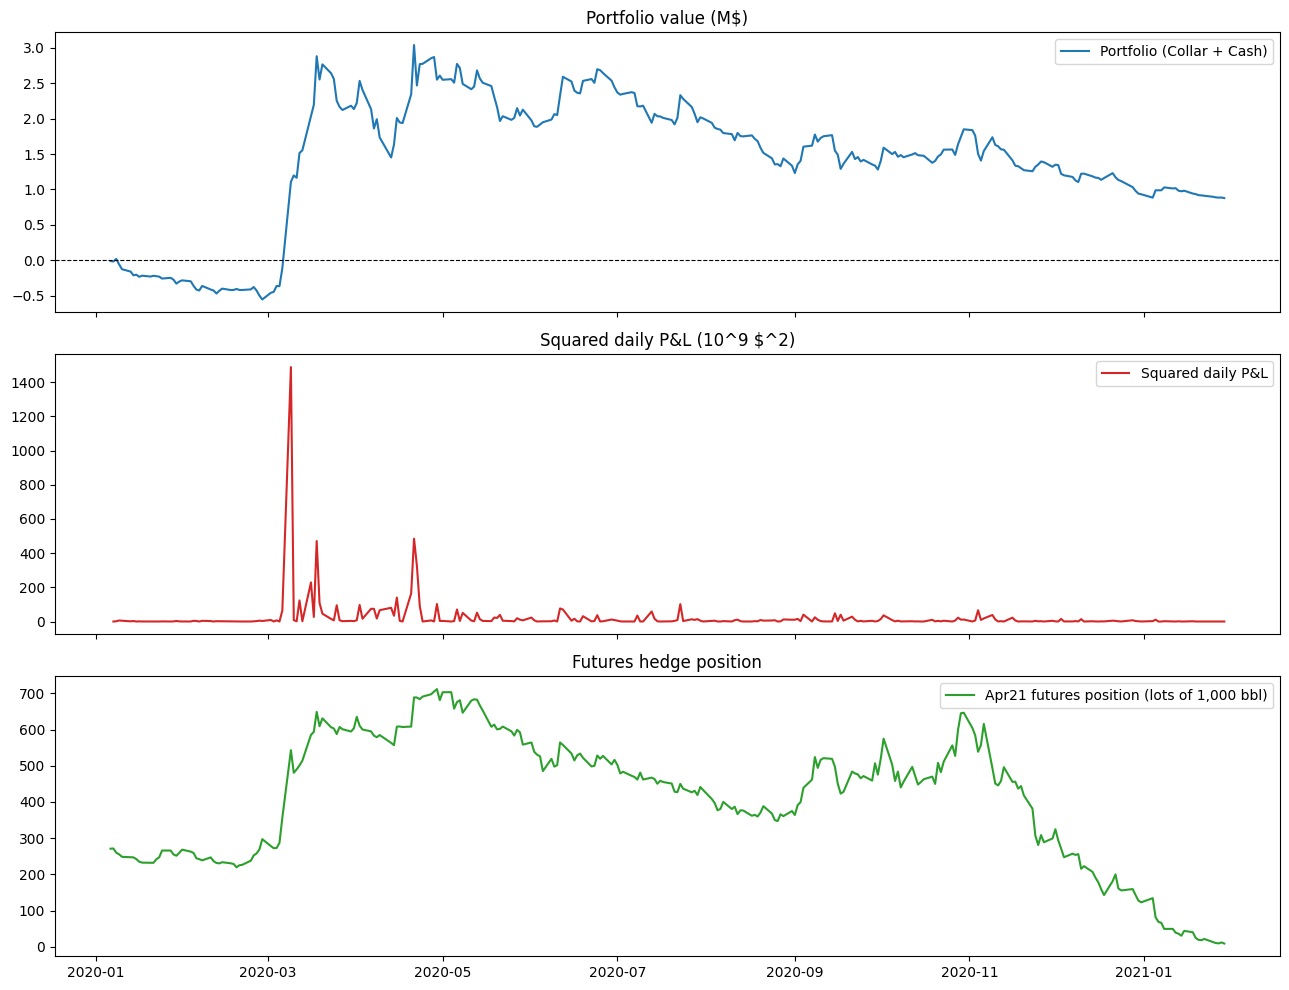

In [12]:
# =============================================================================
# PART 6: DAILY DELTA-NEUTRAL HEDGING BACKTEST
# =============================================================================
days = calibration.index[calibration.index < fixing_dates[0]]
n = len(days)

f = calibration.loc[days, "f1"].to_numpy()
r = sofr.loc[days].to_numpy() / 100.0

fut_daily = (
    df[df["underlying_ticker"] == tickers[0]]
    .drop_duplicates("date")
    .set_index("date")
    .reindex(days)
)
bid_fut = fut_daily["underlying_bid"].to_numpy()
ask_fut = fut_daily["underlying_ask"].to_numpy()
spread = (ask_fut - bid_fut) / 2.0
spread = np.where(np.isnan(spread), np.nanmedian(spread), spread)

# Collar value and parallel delta by central finite differences
V = np.zeros(n)
delta = np.zeros(n)

for i, day in enumerate(days):
    f1 = calibration.at[day, "f1"]
    f2 = calibration.at[day, "f2"]
    rho = calibration.at[day, "rho"]
    D = calibration.at[day, "D"]
    s1 = smiles_by_day[day][tickers[0]]
    s2 = smiles_by_day[day][tickers[1]]
    th1, th2 = fixing_thetas(fixing_dates, n1_sched, day)

    h = 0.001 * f1
    V[i] = collar_value(f1, f2, s1, s2, rho, th1, th2, D, K_put_0)
    V_up = collar_value(f1 + h, f2 + h, s1, s2, rho, th1, th2, D, K_put_0)
    V_down = collar_value(f1 - h, f2 - h, s1, s2, rho, th1, th2, D, K_put_0)
    delta[i] = (V_up - V_down) / (2.0 * h)

def hedging(V, delta, f, r, spread, days):
    """Daily delta-neutral hedging backtest using front-month futures."""
    n = len(days)
    q = np.zeros(n)
    cash = np.zeros(n)
    pnl = np.zeros(n)
    cost = np.zeros(n)
    portfolio = np.zeros(n)

    # Inception (day 0)
    q[0] = -delta[0]
    cost[0] = spread[0] * abs(q[0])
    cash[0] = -cost[0]
    pnl[0] = -cost[0]
    portfolio[0] = V[0] + cash[0]

    for i in range(1, n):
        dt = (days[i] - days[i - 1]).days

        pnl_collar = V[i] - V[i - 1]
        pnl_f = q[i - 1] * (f[i] - f[i - 1])
        interest = cash[i - 1] * r[i - 1] * dt / 365.0

        q[i] = -delta[i]
        cost[i] = spread[i] * abs(q[i] - q[i - 1])

        cash[i] = cash[i - 1] + pnl_f + interest - cost[i]
        pnl[i] = pnl_collar + pnl_f + interest - cost[i]
        portfolio[i] = V[i] + cash[i]

    return pd.DataFrame(
        {
            "V_collar": V,
            "delta": delta,
            "q_futures": q,
            "cash": cash,
            "cost": cost,
            "pnl": pnl,
            "portfolio": portfolio,
        },
        index=days,
    )

bt_delta = hedging(V, delta, f, r, spread, days)

mean_pnl2 = (bt_delta["pnl"].iloc[1:] ** 2).mean()
print("--- DELTA HEDGING RESULTS (6 JAN 2020 -> 29 JAN 2021) ---")
print(f"Mean squared daily P&L : {mean_pnl2:,.0f} $^2")
print(f"RMS daily P&L          : {np.sqrt(mean_pnl2):,.0f} $")
print(f"Worst day              : {bt_delta['pnl'].min():,.0f} $")
print(f"Best day               : {bt_delta['pnl'].max():,.0f} $")
print(f"Total bid-ask costs    : {bt_delta['cost'].sum():,.0f} $")
print(f"Final portfolio value  : {bt_delta['portfolio'].iloc[-1]:,.0f} $")

fig, ax = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
ax[0].plot(bt_delta["portfolio"] / 1e6, label="Portfolio (Collar + Cash)")
ax[0].axhline(0, color="k", lw=0.8, ls="--")
ax[0].set_title("Portfolio value (M$)")
ax[0].legend()

ax[1].plot((bt_delta["pnl"].iloc[1:] ** 2) / 1e9, color="tab:red", label="Squared daily P&L")
ax[1].set_title("Squared daily P&L (10^9 $^2)")
ax[1].legend()

ax[2].plot(bt_delta["q_futures"] / 1000, color="tab:green", label="Apr21 futures position (lots of 1,000 bbl)")
ax[2].set_title("Futures hedge position")
ax[2].legend()

plt.tight_layout()
plt.show()